# Módulo 3 — Práctica Día 5: verificación de integridad y preprocesamiento

Ejercicios de la práctica del **Día 5** (ver [`README.md`](../README.md)).
Se trabaja sobre los archivos **reales** generados el Día 4
(`era5_global_dia4.nc`, y descargas frescas de GFS/FNL), en la misma
carpeta de este notebook.

> **📍 Nota para curso con 2 grupos:** de los 4 casos de fallo del Ejercicio 2, repartir 2 por grupo para cubrir los 4 entre ambos en la puesta en común:
> - **Grupo 1:** Caso A (truncado) y Caso C (casi vacío).
> - **Grupo 2:** Caso B (cobertura insuficiente) y Caso D (ruta inexistente).
> Los Ejercicios 3 y 4 (conversión y `obtener_entrada_wrf()`) se trabajan igual en ambos grupos — ya heredan la estación asignada del Día 4.

## Ejercicio 1 — Verificación en capas (45 min)

Tres controles encadenados: (1) tamaño y existencia, (2) apertura sin
error, (3) cobertura esperada. Se prueba sobre el archivo real de ERA5
descargado el Día 4 (`era5_global_dia4.nc`, 4 pasos de tiempo).

In [1]:
import os
import xarray as xr


def verificar_integridad(archivo, cobertura_esperada=None, tamano_minimo_kb=1, filtro_grib=None):
    """Devuelve (ok: bool, mensaje: str).

    cobertura_esperada: dict opcional, p.ej. {"time_min_horas": 4}
    filtro_grib: dict opcional para GRIB2 con varios tipos de nivel en el
    mismo archivo (p.ej. FNL), pasado como filter_by_keys de cfgrib.
    """
    # Control 1: existencia y tamaño
    if not os.path.exists(archivo):
        return False, f"El archivo {archivo} no existe."
    tamano_kb = os.path.getsize(archivo) / 1024
    if tamano_kb < tamano_minimo_kb:
        return False, f"Archivo sospechosamente pequeño ({tamano_kb:.1f} KB)."

    # Control 2: apertura sin error
    try:
        if archivo.endswith((".grib", ".grib2")):
            kwargs = {"filter_by_keys": filtro_grib} if filtro_grib else {}
            ds = xr.open_dataset(archivo, engine="cfgrib", backend_kwargs=kwargs)
        else:
            ds = xr.open_dataset(archivo)
    except Exception as e:
        return False, f"No se pudo abrir el archivo: {type(e).__name__}: {e}"

    # Control 3: cobertura esperada
    if cobertura_esperada and "time_min_horas" in cobertura_esperada:
        n_tiempos = ds.sizes.get("valid_time", ds.sizes.get("time", 1))
        minimo = cobertura_esperada["time_min_horas"]
        if n_tiempos < minimo:
            return False, (f"Cobertura insuficiente: se esperaban al menos "
                            f"{minimo} pasos de tiempo, el archivo tiene {n_tiempos}.")

    return True, "OK: tamaño, apertura y cobertura verificados."


ok, mensaje = verificar_integridad("era5_global_dia4.nc", cobertura_esperada={"time_min_horas": 4})
print(ok, "-", mensaje)

/home/japq/.conda/envs/jap/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True - OK: tamaño, apertura y cobertura verificados.


## Ejercicio 2 — Provocar y detectar un fallo real (35 min)

In [2]:
# Caso A: archivo truncado (copia cortada a la mitad) del ERA5 real del Día 4
with open("era5_global_dia4.nc", "rb") as f_orig:
    contenido = f_orig.read()

with open("era5_truncado.nc", "wb") as f_trunc:
    f_trunc.write(contenido[: len(contenido) // 2])

ok, mensaje = verificar_integridad("era5_truncado.nc")
print("Caso A (archivo truncado):", ok, "-", mensaje)

Caso A (archivo truncado): False - No se pudo abrir el archivo: OSError: [Errno -101] NetCDF: HDF error: '/p1-swell/japq/loca/unalm/src/modulo_03_descarga_datos_entrada/notebooks/era5_truncado.nc'


In [3]:
# Caso B: archivo real y válido, pero se le pide más cobertura de la que tiene
ok, mensaje = verificar_integridad(
    "era5_global_dia4.nc",
    cobertura_esperada={"time_min_horas": 999},  # pedimos mucho más de lo que tiene
)
print("Caso B (cobertura insuficiente):", ok, "-", mensaje)

Caso B (cobertura insuficiente): False - Cobertura insuficiente: se esperaban al menos 999 pasos de tiempo, el archivo tiene 4.


**Refuerzo — completar los 3 controles.** Los Casos A y B disparan los
controles 2 (apertura) y 3 (cobertura), pero el control 1 (tamaño mínimo)
nunca falló todavía. Se agregan dos casos más para que cada uno de los 3
controles tenga su propio caso de fallo demostrado, no solo 2 de 3.

In [4]:
# Caso C: archivo "descargado" casi vacío (p. ej. la respuesta de un error
# HTTP guardada por error como si fuera el archivo de datos)
with open("era5_vacio.nc", "wb") as f:
    f.write(b"error 404")  # unos pocos bytes, no un NetCDF real

ok, mensaje = verificar_integridad("era5_vacio.nc")
print("Caso C (archivo casi vacío):", ok, "-", mensaje)

Caso C (archivo casi vacío): False - Archivo sospechosamente pequeño (0.0 KB).


In [5]:
# Caso D: la ruta ni siquiera existe (p. ej. un typo en el nombre del archivo)
ok, mensaje = verificar_integridad("era5_que_no_existe.nc")
print("Caso D (archivo inexistente):   ", ok, "-", mensaje)

print()
print("Resumen: cada uno de los 3 controles de la función tiene ahora su propio caso de fallo real:")
print("  Control 1 (tamaño/existencia) -> Casos C y D")
print("  Control 2 (apertura sin error) -> Caso A (truncado)")
print("  Control 3 (cobertura esperada) -> Caso B")

Caso D (archivo inexistente):    False - El archivo era5_que_no_existe.nc no existe.

Resumen: cada uno de los 3 controles de la función tiene ahora su propio caso de fallo real:
  Control 1 (tamaño/existencia) -> Casos C y D
  Control 2 (apertura sin error) -> Caso A (truncado)
  Control 3 (cobertura esperada) -> Caso B


## Ejercicio 2b — Integridad de un CSV de estaciones (SENAMHI) (20 min)

Los archivos de SENAMHI del Día 4 también se verifican, con los **mismos 3
controles**, adaptados a un archivo de texto:

1. **¿Existe y tiene un tamaño razonable?** Igual que antes.
2. **¿Se puede leer bien?** Un CSV casi nunca da error al abrirlo. El
   peligro es otro: que una fila tenga más o menos valores que nombres
   tiene el encabezado, y las columnas queden **corridas**.
3. **¿Trae lo que pedí?** Un mes tiene 24 × días horas; se cuentan las que
   faltan y las que dicen `S/D` («sin dato»).

In [ ]:
import calendar
import pandas as pd

RUTA_SENAMHI = "../../../data/senamhi/"


def verificar_csv_senamhi(ruta, anio, mes, max_horas_faltantes=0, tamano_minimo_kb=1):
    """Los mismos 3 controles, adaptados a un CSV de estacion de SENAMHI.
    Devuelve (ok: bool, mensaje: str)."""
    # Control 1: existencia y tamano
    if not os.path.exists(ruta):
        return False, f"El archivo {ruta} no existe."
    if os.path.getsize(ruta) / 1024 < tamano_minimo_kb:
        return False, "Archivo sospechosamente pequeno."

    # Control 2: se puede leer BIEN -- cada fila tiene tantos valores como
    # nombres tiene el encabezado (si no, las columnas quedan corridas)
    with open(ruta, encoding="utf-8") as f:
        n_encabezado = len(f.readline().strip().split(";"))
        n_por_fila = {len(linea.strip().split(";")) for linea in f if linea.strip()}
    if n_por_fila != {n_encabezado}:
        return False, (f"Columnas corridas: el encabezado tiene {n_encabezado} nombres "
                       f"y las filas tienen {sorted(n_por_fila)} valores.")

    # Control 3: cobertura -- estan todas las horas del mes?
    d = pd.read_csv(ruta, sep=";", dtype=str)
    horas_esperadas = calendar.monthrange(anio, mes)[1] * 24
    faltan = horas_esperadas - len(d)
    sin_dato = int((d["Temperatura (°C)"] == "S/D").sum())
    if faltan > max_horas_faltantes:
        return False, (f"Faltan {faltan} de {horas_esperadas} horas "
                       f"(y {sin_dato} horas con S/D en temperatura).")
    return True, f"OK: faltan {faltan} horas, {sin_dato} con S/D en temperatura."


for archivo in ["112265_2025_03.csv", "112181_2025_03.csv", "472AC278_2025_03.csv",
                "112278_2025_03.csv", "111290_2025_03.csv"]:
    ok, mensaje = verificar_csv_senamhi(RUTA_SENAMHI + archivo, 2025, 3)
    print(f"{archivo:22s} {ok!s:5s} - {mensaje}")

112265_2025_03.csv     False - Faltan 7 de 744 horas (y 0 horas con S/D en temperatura).
112181_2025_03.csv     True  - OK: faltan 0 horas, 2 con S/D en temperatura.
472AC278_2025_03.csv   False - Faltan 1 de 744 horas (y 0 horas con S/D en temperatura).
112278_2025_03.csv     False - Faltan 7 de 744 horas (y 0 horas con S/D en temperatura).
111290_2025_03.csv     True  - OK: faltan 0 horas, 2 con S/D en temperatura.


Que falten 7 horas, ¿invalida el archivo? Depende del uso: para un
promedio mensual no importa; para comparar con el WRF justo esas horas, sí.
Por eso la tolerancia es un parámetro (`max_horas_faltantes`), que decide
quien usa los datos.

**Caso E — columnas corridas (un error real de este curso).** Ceres no
tiene sensor de humedad: sus filas traen 8 valores. Pero la descarga
original le puso el encabezado de 9 columnas de las otras estaciones (con
`Humedad (%)`). Lo reproducimos tal cual:

In [ ]:
# Mismas filas reales de Ceres, con el encabezado que traía la descarga original
with open(RUTA_SENAMHI + "112278_2025_03.csv", encoding="utf-8") as f:
    f.readline()                 # se descarta el encabezado corregido
    filas_ceres = f.read()

encabezado_original = ("Año;Mes;Día;Hora;Temperatura (°C);Precipitación (mm);"
                       "Humedad (%);Dir. Viento (°);Vel. Viento (m/s)\n")
with open("ceres_como_se_descargo.csv", "w", encoding="utf-8") as f:
    f.write(encabezado_original + filas_ceres)

ok, mensaje = verificar_csv_senamhi("ceres_como_se_descargo.csv", 2025, 3)
print("Caso E (columnas corridas):", ok, "-", mensaje)

Caso E (columnas corridas): False - Columnas corridas: el encabezado tiene 9 nombres y las filas tienen [8] valores.


In [ ]:
# Y lo que pasa si NO se verifica: pandas lo lee sin ningún error...
d = pd.read_csv("ceres_como_se_descargo.csv", sep=";")
d[["Hora", "Humedad (%)", "Dir. Viento (°)", "Vel. Viento (m/s)"]].head()

,Hora,Humedad (%),Dir. Viento (°),Vel. Viento (m/s)
0,00:00,27.74,0.0,NaN
1,01:00,63.55,0.1,NaN
2,02:00,26.03,0.0,NaN
3,03:00,74.17,0.2,NaN
4,04:00,14.69,0.0,NaN


Pandas no se quejó, pero la tabla miente: la columna «Humedad» trae en
realidad la **dirección del viento** (valores como 27.74 o 63.55), la de
dirección trae la **velocidad**, y la velocidad quedó vacía (`NaN`).
Cualquier gráfico o promedio hecho con esto sería falso, y nada avisaría.
El control 2 lo detecta en una línea. (En `data/senamhi/` el encabezado de
Ceres ya está corregido.)

## Ejercicio 3 — Conversión y organización (40 min)

Convertir a NetCDF y organizar, siguiendo la convención
`datos/<fuente>/<rango-de-fechas>.nc` discutida en el README, las **tres**
fuentes reales del módulo: GFS (Herbie), ERA5 (cdsapi) y FNL (HTTPS
directo). Se descarga un mensaje fresco de GFS con Herbie (mismo patrón
del Día 4) para tener un GRIB2 real que convertir.

In [6]:
from herbie import Herbie

os.makedirs("datos/entrada/gfs", exist_ok=True)
os.makedirs("datos/entrada/era5", exist_ok=True)
os.makedirs("datos/entrada/fnl", exist_ok=True)

h = Herbie("2025-03-15 00:00", model="gfs", product="pgrb2.0p25", fxx=0,
           priority=["aws", "google"])
ruta_gfs_grib2 = str(h.download(":TMP:2 m above ground"))
print("GRIB2 real descargado por Herbie en:", ruta_gfs_grib2)

ds_gfs = xr.open_dataset(ruta_gfs_grib2, engine="cfgrib")
ruta_gfs = "datos/entrada/gfs/2025-03-15_f00.nc"
ds_gfs.to_netcdf(ruta_gfs)
print("GFS convertido y guardado en:      ", ruta_gfs)

# ERA5 real del Día 4 ya estaba en NetCDF; solo se organiza en la carpeta convenida
import shutil
ruta_era5 = "datos/entrada/era5/2025-03-15.nc"
shutil.copy("era5_global_dia4.nc", ruta_era5)
print("ERA5 organizado en:                ", ruta_era5)

✅ Found ┊ model=gfs ┊ product=pgrb2.0p25 ┊ 2025-Mar-15 00:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local


GRIB2 real descargado por Herbie en: /p1-swell/japq/bigua/datos/gfs/20250315/subset_d9ef22b0__gfs.t00z.pgrb2.0p25.f000


GFS convertido y guardado en:       datos/entrada/gfs/2025-03-15_f00.nc
ERA5 organizado en:                 datos/entrada/era5/2025-03-15.nc


**FNL real: un caso distinto.** A diferencia de GFS/ERA5 (un solo tipo de
nivel), el GRIB2 crudo de FNL trae varios tipos de nivel en el mismo
archivo (`heightAboveGround`, `meanSea`, `surface`, ...) — abrirlo sin
`filter_by_keys` falla, como se vio en el notebook de teoría. La conversión
a NetCDF resuelve esto una sola vez: después de convertir, el archivo
organizado ya es un NetCDF de un solo grupo, abrible sin filtro.

In [7]:
RUTA_DATOS = "../../../data"
archivo_fnl = os.path.join(RUTA_DATOS, "gdas1.fnl0p25.2025031500.f00.grib2")

ds_fnl = xr.open_dataset(
    archivo_fnl, engine="cfgrib",
    backend_kwargs={"filter_by_keys": {"typeOfLevel": "heightAboveGround", "level": 2}},
)
ruta_fnl = "datos/entrada/fnl/2025-03-15_f00.nc"
ds_fnl.to_netcdf(ruta_fnl)
print("FNL convertido y guardado en:      ", ruta_fnl)

Ignoring index file '../../../data/gdas1.fnl0p25.2025031500.f00.grib2.da267.idx' incompatible with GRIB file


FNL convertido y guardado en:       datos/entrada/fnl/2025-03-15_f00.nc


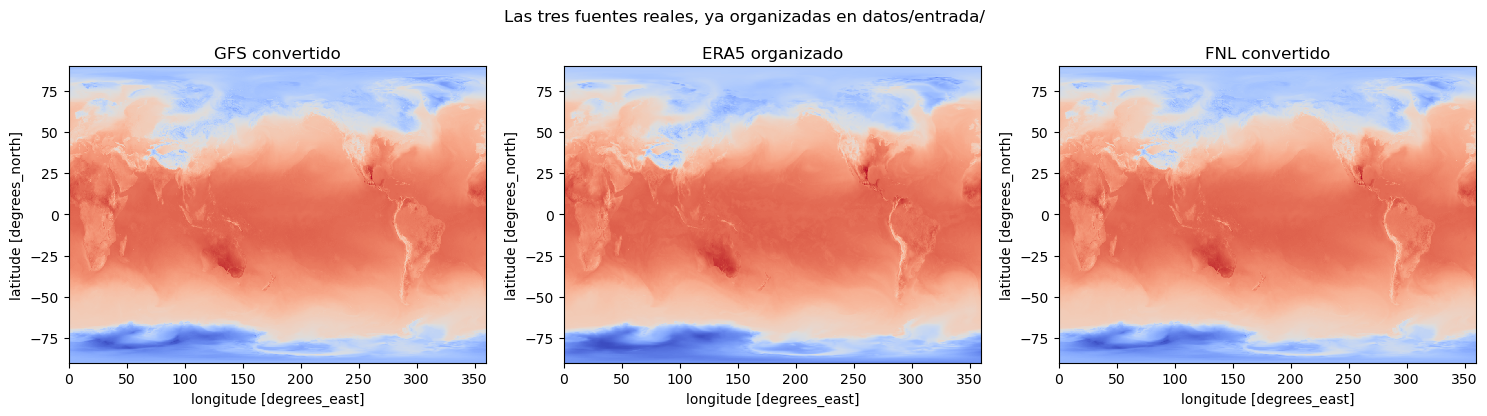

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
xr.open_dataset(ruta_gfs)["t2m"].plot(ax=axes[0], cmap="coolwarm", add_colorbar=False)
axes[0].set_title("GFS convertido")
xr.open_dataset(ruta_era5)["t2m"].isel(valid_time=0).plot(ax=axes[1], cmap="coolwarm", add_colorbar=False)
axes[1].set_title("ERA5 organizado")
xr.open_dataset(ruta_fnl)["t2m"].plot(ax=axes[2], cmap="coolwarm", add_colorbar=False)
axes[2].set_title("FNL convertido")
fig.suptitle("Las tres fuentes reales, ya organizadas en datos/entrada/")
fig.tight_layout()
plt.show()

**Refuerzo — organizar no es lo mismo que verificar.** Copiar/convertir un
archivo a su carpeta final puede fallar en silencio (disco lleno a mitad
de la escritura, permiso denegado que trunca la copia). La función
`verificar_integridad()` del Ejercicio 1 ya está escrita — no cuesta nada
volver a llamarla sobre el resultado FINAL organizado, no solo confiar en
que "no tiró error" al copiar. El caso de FNL además necesita su
`filtro_grib` original si se verificara el `.grib2` crudo, pero como aquí
ya se organizó como NetCDF, no hace falta pasarlo.

In [ ]:
# Las rutas se escriben aquí (no se usan variables de celdas anteriores):
# si una conversión falló, verificar_integridad lo dice, en vez de un NameError.
for nombre, ruta, cobertura in [
    ("GFS convertido", "datos/entrada/gfs/2025-03-15_f00.nc", None),
    ("ERA5 organizado", "datos/entrada/era5/2025-03-15.nc", {"time_min_horas": 4}),
    ("FNL convertido", "datos/entrada/fnl/2025-03-15_f00.nc", None),
]:
    ok, mensaje = verificar_integridad(ruta, cobertura_esperada=cobertura)
    print(f"{nombre:16s} [{ruta}] -> {ok} - {mensaje}")

## Ejercicio 4 — Función integradora `obtener_entrada_wrf()` (40 min)

Hasta acá cada descarga trajo 1-2 variables, para aprender la mecánica de
cada API (Sección 5 de la teoría). Un archivo que de verdad sirve para
correr WRF necesita **todo lo que pide el Vtable** — no una lista de
variables a elección del usuario. Por eso `descargar_era5_completo()` ya
no recibe `variables` como parámetro: siempre pide el conjunto fijo que
exige `Vtable.ERA5` (adaptado al producto `cdsapi` con niveles de presión
fijos, ver teoría), con `area` acotada al dominio del WRF — el patrón del
Ejercicio 5 del Día 4, porque aquí sí se sabe de antemano el dominio final.

In [10]:
import cdsapi
import pandas as pd

# Campos de Vtable.ERA5 (unalm/data/Vtable.ERA5), agrupados por dataset de
# cdsapi. Niveles de presión: TT/UU/VV/SPECHUMD del Vtable + geopotencial
# ("z"), agregado porque el producto por niveles fijos de cdsapi no trae
# LOGSFP (ese campo es propio del acceso nativo a MARS por niveles
# hibridos, no de este producto -- ver teoria, Seccion 5).
NIVELES_PRESION_ERA5 = [1, 2, 3, 5, 7, 10, 20, 30, 50, 70, 100, 125, 150, 175,
                         200, 225, 250, 300, 350, 400, 450, 500, 550, 600,
                         650, 700, 750, 775, 800, 825, 850, 875, 900, 925,
                         950, 975, 1000]
VARIABLES_PRESION_ERA5 = [
    "temperature", "u_component_of_wind", "v_component_of_wind",
    "specific_humidity", "geopotential",
]
# Superficie: TT/RH(via DEWPT)/UU/VV a 2/10 m, PSFC, PMSL, SKINTEMP,
# SEAICE, SNOW, LANDSEA, SOILHGT (geopotencial de superficie), y las 4
# capas de suelo con los limites propios de ECMWF (0-7/7-28/28-100/100-289 cm).
VARIABLES_SUPERFICIE_ERA5 = [
    "2m_temperature", "2m_dewpoint_temperature",
    "10m_u_component_of_wind", "10m_v_component_of_wind",
    "surface_pressure", "mean_sea_level_pressure",
    "skin_temperature", "sea_ice_cover", "snow_depth", "land_sea_mask",
    "geopotential",
    "soil_temperature_level_1", "soil_temperature_level_2",
    "soil_temperature_level_3", "soil_temperature_level_4",
    "volumetric_soil_water_layer_1", "volumetric_soil_water_layer_2",
    "volumetric_soil_water_layer_3", "volumetric_soil_water_layer_4",
]


def _pedido_era5(fecha_inicio, fecha_fin, area, variables, extra, destino):
    if os.path.exists(destino):
        print(f"Ya existe {destino}, no se vuelve a pedir al servidor.")
        return destino
    dias = pd.date_range(fecha_inicio, fecha_fin, freq="D")
    horas = [f"{h:02d}:00" for h in range(0, 24, 6)]
    peticion = {
        "product_type": "reanalysis",
        "variable": variables,
        "year": dias[0].strftime("%Y"),
        "month": dias[0].strftime("%m"),
        "day": sorted({d.strftime("%d") for d in dias}),
        "time": horas,
        "area": area,
        "format": "netcdf",
    }
    peticion.update(extra)
    dataset = "reanalysis-era5-pressure-levels" if "pressure_level" in extra else "reanalysis-era5-single-levels"
    cdsapi.Client().retrieve(dataset, peticion, destino)
    return destino


def descargar_era5_completo(fecha_inicio, fecha_fin, area, carpeta_destino):
    """Descarga real de ERA5 via cdsapi con TODO lo que pide Vtable.ERA5
    (niveles de presion + superficie) -- no una lista de variables a
    eleccion, porque eso es justamente lo que hace falta para que WPS no
    falle. area=[norte, oeste, sur, este]. Devuelve (ruta_niveles, ruta_superficie).
    """
    os.makedirs(carpeta_destino, exist_ok=True)
    nombre = f"{fecha_inicio}_{fecha_fin}"
    ruta_niveles = os.path.join(carpeta_destino, f"{nombre}_niveles_presion.nc")
    ruta_superficie = os.path.join(carpeta_destino, f"{nombre}_superficie.nc")

    _pedido_era5(fecha_inicio, fecha_fin, area, VARIABLES_PRESION_ERA5,
                 {"pressure_level": [str(p) for p in NIVELES_PRESION_ERA5]},
                 ruta_niveles)
    _pedido_era5(fecha_inicio, fecha_fin, area, VARIABLES_SUPERFICIE_ERA5,
                 {}, ruta_superficie)
    return ruta_niveles, ruta_superficie


def verificar_cobertura_vtable(archivo, nombres_cds_esperados):
    """Control adicional: confirma que TODAS las variables que pide el
    Vtable estan presentes (nombres cortos con los que cdsapi realmente
    guarda cada una, no el nombre largo de la solicitud). Devuelve (ok, msg)."""
    ds = xr.open_dataset(archivo)
    faltan = set(nombres_cds_esperados) - set(ds.data_vars)
    if faltan:
        return False, f"Faltan variables del Vtable: {sorted(faltan)}"
    return True, f"OK: {len(nombres_cds_esperados)}/{len(nombres_cds_esperados)} variables del Vtable presentes."


NOMBRES_CORTOS_PRESION = ["t", "u", "v", "q", "z"]
NOMBRES_CORTOS_SUPERFICIE = ["t2m", "d2m", "u10", "v10", "sp", "msl", "skt",
                              "siconc", "sd", "lsm", "z",
                              "stl1", "stl2", "stl3", "stl4",
                              "swvl1", "swvl2", "swvl3", "swvl4"]


def obtener_entrada_wrf(fecha_inicio, fecha_fin, area, carpeta_destino):
    """Descarga COMPLETA (todo lo que pide Vtable.ERA5) -> verifica ->
    dice si quedo lista para usarse. Devuelve (ok: bool, resultado)."""
    try:
        ruta_niveles, ruta_superficie = descargar_era5_completo(
            fecha_inicio, fecha_fin, area, carpeta_destino)
    except Exception as e:
        return False, f"Fallo en la descarga: {type(e).__name__}: {e}"

    n_dias = (pd.Timestamp(fecha_fin) - pd.Timestamp(fecha_inicio)).days + 1
    horas_esperadas = n_dias * 4

    for ruta, nombres_cortos in [(ruta_niveles, NOMBRES_CORTOS_PRESION),
                                  (ruta_superficie, NOMBRES_CORTOS_SUPERFICIE)]:
        ok, mensaje = verificar_integridad(ruta, cobertura_esperada={"time_min_horas": horas_esperadas})
        if not ok:
            return False, f"Fallo en la verificación de {ruta}: {mensaje}"
        ok, mensaje = verificar_cobertura_vtable(ruta, nombres_cortos)
        if not ok:
            return False, f"Fallo en la cobertura Vtable de {ruta}: {mensaje}"

    return True, (ruta_niveles, ruta_superficie)


# Fecha nueva, no usada en ningún otro notebook del módulo
ok, resultado = obtener_entrada_wrf(
    fecha_inicio="2024-09-05", fecha_fin="2024-09-05",
    area=[2, -81, -17, -69],
    carpeta_destino="datos/entrada/era5",
)
print("¿Éxito?", ok)
print("Resultado:", resultado)

2026-07-24 20:17:41,414 INFO Request ID is 20d8a99d-9587-4421-9bbe-186bc23fc2c1


2026-07-24 20:17:42,261 INFO status has been updated to accepted


2026-07-24 20:18:16,387 INFO status has been updated to running


2026-07-24 20:19:01,515 INFO status has been updated to successful


f4f24460eca6af8a279619b3de4456b8.nc:   0%|                                                             | 0.00/4.81M [00:00<?, ?B/s]

...

2026-07-24 20:19:10,060 INFO status has been updated to accepted


2026-07-24 20:19:44,868 INFO status has been updated to successful


88a3bfe87f6f5f2b15ed0e78c97b6288.nc:   0%|                                                              | 0.00/611k [00:00<?, ?B/s]

88a3bfe87f6f5f2b15ed0e78c97b6288.nc: 100%|███████████████████████████████████████████████████████| 611k/611k [00:01<00:00, 323kB/s]

¿Éxito? True
Resultado: ('datos/entrada/era5/2024-09-05_2024-09-05_niveles_presion.nc', 'datos/entrada/era5/2024-09-05_2024-09-05_superficie.nc')


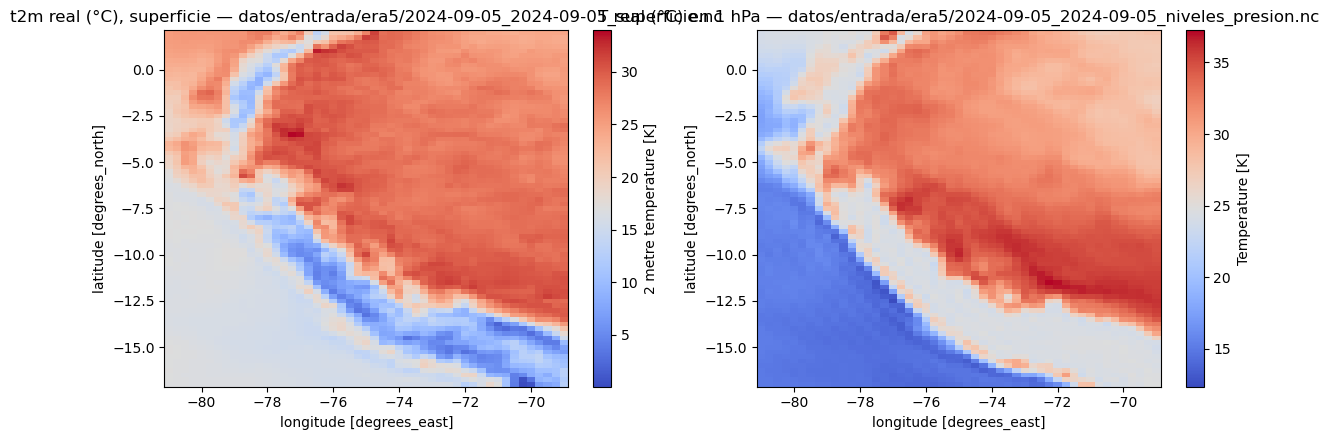

In [11]:
if ok:
    ruta_niveles, ruta_superficie = resultado
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    (xr.open_dataset(ruta_superficie)["t2m"].isel(valid_time=0) - 273.15).plot(ax=axes[0], cmap="coolwarm")
    axes[0].set_title(f"t2m real (°C), superficie — {ruta_superficie}")
    (xr.open_dataset(ruta_niveles)["t"].isel(valid_time=0, pressure_level=0) - 273.15).plot(ax=axes[1], cmap="coolwarm")
    axes[1].set_title(f"T real (°C) en {NIVELES_PRESION_ERA5[0]} hPa — {ruta_niveles}")
    fig.tight_layout()
    plt.show()

## Cierre del módulo

Entregable: módulo `descarga.py` — en la práctica se recomienda mover
`verificar_integridad`, `verificar_csv_senamhi`, `verificar_cobertura_vtable`,
`descargar_era5_completo` y `obtener_entrada_wrf` a un archivo `.py`
reutilizable (se hace explícitamente en el
[Módulo 6](../../modulo_06_pipeline_integrado/README.md)). Aquí se guardan
directamente para referencia futura.

In [ ]:
codigo_modulo = '''# Funciones reales de descarga y verificacion (Modulo 3)
import calendar
import os
import cdsapi
import xarray as xr
import pandas as pd


def verificar_integridad(archivo, cobertura_esperada=None, tamano_minimo_kb=1, filtro_grib=None):
    if not os.path.exists(archivo):
        return False, f"El archivo {archivo} no existe."
    tamano_kb = os.path.getsize(archivo) / 1024
    if tamano_kb < tamano_minimo_kb:
        return False, f"Archivo sospechosamente pequeno ({tamano_kb:.1f} KB)."
    try:
        if archivo.endswith((".grib", ".grib2")):
            kwargs = {"filter_by_keys": filtro_grib} if filtro_grib else {}
            ds = xr.open_dataset(archivo, engine="cfgrib", backend_kwargs=kwargs)
        else:
            ds = xr.open_dataset(archivo)
    except Exception as e:
        return False, f"No se pudo abrir el archivo: {type(e).__name__}: {e}"
    if cobertura_esperada and "time_min_horas" in cobertura_esperada:
        n_tiempos = ds.sizes.get("valid_time", ds.sizes.get("time", 1))
        minimo = cobertura_esperada["time_min_horas"]
        if n_tiempos < minimo:
            return False, f"Cobertura insuficiente: {n_tiempos} < {minimo}."
    return True, "OK"


NIVELES_PRESION_ERA5 = [1, 2, 3, 5, 7, 10, 20, 30, 50, 70, 100, 125, 150, 175,
                         200, 225, 250, 300, 350, 400, 450, 500, 550, 600,
                         650, 700, 750, 775, 800, 825, 850, 875, 900, 925,
                         950, 975, 1000]
VARIABLES_PRESION_ERA5 = ["temperature", "u_component_of_wind",
                           "v_component_of_wind", "specific_humidity", "geopotential"]
VARIABLES_SUPERFICIE_ERA5 = [
    "2m_temperature", "2m_dewpoint_temperature",
    "10m_u_component_of_wind", "10m_v_component_of_wind",
    "surface_pressure", "mean_sea_level_pressure",
    "skin_temperature", "sea_ice_cover", "snow_depth", "land_sea_mask",
    "geopotential",
    "soil_temperature_level_1", "soil_temperature_level_2",
    "soil_temperature_level_3", "soil_temperature_level_4",
    "volumetric_soil_water_layer_1", "volumetric_soil_water_layer_2",
    "volumetric_soil_water_layer_3", "volumetric_soil_water_layer_4",
]
NOMBRES_CORTOS_PRESION = ["t", "u", "v", "q", "z"]
NOMBRES_CORTOS_SUPERFICIE = ["t2m", "d2m", "u10", "v10", "sp", "msl", "skt",
                              "siconc", "sd", "lsm", "z",
                              "stl1", "stl2", "stl3", "stl4",
                              "swvl1", "swvl2", "swvl3", "swvl4"]


def _pedido_era5(fecha_inicio, fecha_fin, area, variables, extra, destino):
    if os.path.exists(destino):
        return destino
    dias = pd.date_range(fecha_inicio, fecha_fin, freq="D")
    if len(dias) == 0:
        raise ValueError(f"fecha_fin ({fecha_fin}) es anterior a fecha_inicio ({fecha_inicio}).")
    if (dias[0].year, dias[0].month) != (dias[-1].year, dias[-1].month):
        raise ValueError("El periodo cruza de un mes a otro: CDS necesita un pedido por mes.")
    horas = [f"{h:02d}:00" for h in range(0, 24, 6)]
    peticion = {
        "product_type": "reanalysis",
        "variable": variables,
        "year": dias[0].strftime("%Y"),
        "month": dias[0].strftime("%m"),
        "day": sorted({d.strftime("%d") for d in dias}),
        "time": horas,
        "area": area,
        "format": "netcdf",
    }
    peticion.update(extra)
    dataset = "reanalysis-era5-pressure-levels" if "pressure_level" in extra else "reanalysis-era5-single-levels"
    cdsapi.Client().retrieve(dataset, peticion, destino)
    return destino


def descargar_era5_completo(fecha_inicio, fecha_fin, area, carpeta_destino):
    os.makedirs(carpeta_destino, exist_ok=True)
    nombre = f"{fecha_inicio}_{fecha_fin}"
    ruta_niveles = os.path.join(carpeta_destino, f"{nombre}_niveles_presion.nc")
    ruta_superficie = os.path.join(carpeta_destino, f"{nombre}_superficie.nc")
    _pedido_era5(fecha_inicio, fecha_fin, area, VARIABLES_PRESION_ERA5,
                 {"pressure_level": [str(p) for p in NIVELES_PRESION_ERA5]}, ruta_niveles)
    _pedido_era5(fecha_inicio, fecha_fin, area, VARIABLES_SUPERFICIE_ERA5, {}, ruta_superficie)
    return ruta_niveles, ruta_superficie


def verificar_cobertura_vtable(archivo, nombres_cds_esperados):
    ds = xr.open_dataset(archivo)
    faltan = set(nombres_cds_esperados) - set(ds.data_vars)
    if faltan:
        return False, f"Faltan variables del Vtable: {sorted(faltan)}"
    return True, "OK"


def obtener_entrada_wrf(fecha_inicio, fecha_fin, area, carpeta_destino):
    try:
        ruta_niveles, ruta_superficie = descargar_era5_completo(fecha_inicio, fecha_fin, area, carpeta_destino)
    except Exception as e:
        return False, f"Fallo en la descarga: {type(e).__name__}: {e}"
    n_dias = (pd.Timestamp(fecha_fin) - pd.Timestamp(fecha_inicio)).days + 1
    horas_esperadas = n_dias * 4
    for ruta, nombres_cortos in [(ruta_niveles, NOMBRES_CORTOS_PRESION),
                                  (ruta_superficie, NOMBRES_CORTOS_SUPERFICIE)]:
        ok, msg = verificar_integridad(ruta, {"time_min_horas": horas_esperadas})
        if not ok:
            return False, f"Fallo en la verificación de {ruta}: {msg}"
        ok, msg = verificar_cobertura_vtable(ruta, nombres_cortos)
        if not ok:
            return False, f"Fallo en la cobertura Vtable de {ruta}: {msg}"
    return True, (ruta_niveles, ruta_superficie)


def verificar_csv_senamhi(ruta, anio, mes, max_horas_faltantes=0, tamano_minimo_kb=1):
    """Los mismos 3 controles, adaptados a un CSV de estacion de SENAMHI.
    Devuelve (ok: bool, mensaje: str)."""
    # Control 1: existencia y tamano
    if not os.path.exists(ruta):
        return False, f"El archivo {ruta} no existe."
    if os.path.getsize(ruta) / 1024 < tamano_minimo_kb:
        return False, "Archivo sospechosamente pequeno."

    # Control 2: se puede leer BIEN -- cada fila tiene tantos valores como
    # nombres tiene el encabezado (si no, las columnas quedan corridas)
    with open(ruta, encoding="utf-8") as f:
        n_encabezado = len(f.readline().strip().split(";"))
        n_por_fila = {len(linea.strip().split(";")) for linea in f if linea.strip()}
    if n_por_fila != {n_encabezado}:
        return False, (f"Columnas corridas: el encabezado tiene {n_encabezado} nombres "
                       f"y las filas tienen {sorted(n_por_fila)} valores.")

    # Control 3: cobertura -- estan todas las horas del mes?
    d = pd.read_csv(ruta, sep=";", dtype=str)
    horas_esperadas = calendar.monthrange(anio, mes)[1] * 24
    faltan = horas_esperadas - len(d)
    sin_dato = int((d["Temperatura (°C)"] == "S/D").sum())
    if faltan > max_horas_faltantes:
        return False, (f"Faltan {faltan} de {horas_esperadas} horas "
                       f"(y {sin_dato} horas con S/D en temperatura).")
    return True, f"OK: faltan {faltan} horas, {sin_dato} con S/D en temperatura."
'''

with open("descarga.py", "w") as f:
    f.write(codigo_modulo)
print("Guardado: descarga.py")